# 6장 1강: 전이학습의 기본 원리 — 실습문제

## 실습 목표

- Pretrained Model이 이미 어떤 데이터를 학습한 모델인지 설명합니다.
- 다른 건물에서 배운 특징을 새 건물에 재사용하는 Transfer Learning을 이해합니다.
- Feature Extraction에서 고정되는 부분과 학습되는 부분을 구분합니다.
- Fine-tuning에서 업데이트 범위가 어떻게 달라지는지 실제 파라미터로 확인합니다.

## 실습 구성

| 구분 | 문제 | 내용 |
|---|---|---|
| 실습 1 | 1-1 | 데이터 구분과 교육용 사전학습 모델 만들기 |
| 실습 1 | 1-2 | 사전학습 특징 추출과 출력층 학습 |
| 실습 2 | 2-1 | 작은 학습률로 미세조정하고 변경 부분 확인 |
| 실습 2 | 2-2 | 대상 건물에서 세 단계의 결과 해석 |
| 기초 과제 | 3-1 | 같은 조건에서 은닉층 고정 여부만 바꾸어 비교 |

**실습 2개 + 기초 과제 1개**입니다. 신경망의 순전파·역전파 학습 함수는 완성된 코드로 제공합니다. 함수를 새로 구현하거나 최적 성능을 찾는 과제가 아닙니다.

제공된 **6장 1강 목차: Pretrained Model과 Transfer Learning, Feature Extraction, Fine-tuning**을 기준으로 구성했습니다. 강의 본문은 별도로 제공되지 않았으므로 건물·기간·모델 크기·학습률은 원리를 확인하기 위한 실습 설정입니다.

## 이번 실습의 사전학습 모델

별도 사전학습 모델 파일이 제공되지 않았으므로 **1~4번 건물의 과거 자료로 작은 신경망을 먼저 학습**합니다. 학습이 끝난 그 상태를 5번 건물에 전달합니다. 외부에서 내려받는 대규모 범용 모델이 아니라, 노트북 안에서 직접 준비하는 **교육용 사전학습 모델**입니다.

전력소비량이라는 예측 대상은 같지만 건물과 데이터 분포가 달라집니다. 이런 관련 환경 사이에서도 학습한 특징을 재사용할 수 있습니다. 숫자가 들어 있는 임의의 가중치를 복사하는 것만으로 사전학습이 되는 것은 아닙니다.

## 데이터와 실행 방법

- Python, NumPy, pandas, Matplotlib을 사용합니다. GPU나 별도 딥러닝 프레임워크 설치는 필요하지 않습니다.
- **`전기사용량(2).csv`, `building_info(2).csv`**를 노트북과 같은 폴더에 두세요. 괄호가 없는 `전기사용량.csv`, `building_info.csv`도 읽을 수 있습니다.
- 전력 파일은 시간별 관측 204,000행·10열, 건물 파일은 100행·7열입니다. `건물번호`로 건물의 연면적·냉방면적 등을 연결합니다.
- 입력은 **기온, 습도, 시간, 요일, 연면적, 냉방면적**의 6개입니다. `hour`는 0~23, `weekday`는 월요일 0~일요일 6입니다. 시간·요일은 날짜에서 꺼내는 제공 전처리입니다.
- 정답은 **전력소비량(kWh)**입니다. 같은 시간의 기상 조건을 입력으로 사용하는 회귀 예제이며, 미래 기상을 모르는 상태에서 수행하는 다음 날 전력 예측 실험은 아닙니다.
- `건물유형`은 자료 확인에 사용하며 모델 입력에는 넣지 않습니다. 강수량·일조·일사 및 설비 용량은 이번 범위에서 제외합니다. 설비 열의 `-`를 임의로 0으로 바꾸어 사용하지 않습니다.

| 집합 | 건물 | 기간(양 끝 포함) | 행 수 | 역할 |
|---|---|---|---:|---|
| 사전학습 / Source | 1~4번 | 2022-06-01 00시~06-30 23시 | 2,880 | 특징을 먼저 학습 |
| 대상 학습 / Target Train | 5번 | 2022-07-01 00시~07-07 23시 | 168 | 새 건물에 맞게 업데이트 |
| 대상 검증 / Target Validation | 5번 | 2022-07-08 00시~07-14 23시 | 168 | 업데이트 없이 결과 확인 |

건물 번호와 기간은 빠른 실습을 위한 선택이며 최적 조합이라는 뜻은 아닙니다. 나머지 기록은 사용하지 않습니다. 시간 순서를 유지하며, 검증 기간의 정답을 사전학습이나 대상 학습에 사용하지 않습니다.

입력 결측값을 채울 중앙값과 입력·정답의 평균·표준편차는 **Source에서만** 구합니다. 이 기준을 세 집합에 동일하게 적용합니다. 제공 파일의 선택된 입력·기간에는 실제 결측값이 없습니다. 중앙값 처리는 같은 실행 흐름을 유지하기 위한 준비 코드입니다.

Loss는 앞 강의와 같은 MSE이며, 여기서는 **Source 기준으로 표준화된 전력소비량**에서 계산합니다. kWh 오차나 정확도(%)가 아닙니다. 예측값을 `표준화 예측값 × y_std + y_mean`으로 되돌리면 kWh로 읽을 수 있습니다.

## 먼저 알아둘 용어

| 용어 | 이번 실습에서의 의미 |
|---|---|
| Pretrained Model | 1~4번 건물로 학습을 마친 신경망 |
| Transfer Learning | 먼저 배운 은닉층의 특징을 5번 건물 학습에 재사용하는 과정 |
| Backbone / 특징 추출부 | 입력을 8개의 은닉층 출력으로 바꾸는 부분. W1과 b1을 사용 |
| Head / 출력층 | 8개의 특징을 전력소비량 예측 하나로 바꾸는 부분. W2와 b2를 사용 |
| Freeze / 동결 | 순전파 계산은 유지하면서 해당 가중치·편향을 업데이트하지 않는 것 |
| Feature Extraction | 사전학습 은닉층으로 특징을 만들고, 여기서는 그 은닉층을 고정한 채 새 출력층만 학습 |
| Fine-tuning | 이미 학습한 파라미터에서 출발하여 대상 데이터로 일부 또는 전체를 추가 조정. 여기서는 은닉층과 출력층 모두 조정 |

노트북 위에서부터 순서대로 실행하세요. 고정 난수를 사용하지만 환경에 따라 마지막 소수점 자릿수는 달라질 수 있습니다.

### 이 강의에서 ‘배운 것을 가져온다’는 뜻

신경망의 학습은 입력으로 예측값을 계산하고, 실제값과의 오차를 줄이도록 **가중치와 편향이라는 숫자를 수정하는 과정**입니다. 사전학습 모델은 어떤 데이터를 사용하여 이 과정을 이미 수행한 모델입니다. 모델 이름이나 구조가 같다는 이유만으로 사전학습 모델이 되는 것은 아닙니다.

이번에는 1~4번 건물의 자료가 비교적 많고, 5번 건물에 맞추는 데 사용하는 자료는 일주일치입니다. 관련 건물에서 먼저 익힌 계산 방법을 새 건물에서도 출발점으로 활용해 봅니다. 온도·습도·시간 같은 공통 입력과 전력 사용량 사이의 관계를 재사용할 가능성이 있기 때문입니다. 다만 건물별 운영 방식과 사용 규모가 다르므로, 가져온 계산 방법이 실제로 도움이 되는지는 대상 건물의 검증 결과로 확인해야 합니다.

‘지식 전달’은 사람이 정답을 설명해 주는 행위가 아니라 **학습된 파라미터 값을 가져오는 것**입니다. 모델의 구조와 입력 처리 방법도 그 값에 맞아야 합니다. 예를 들어 기온에 곱하도록 배운 가중치 자리에 갑자기 면적을 넣으면 같은 의미의 계산을 할 수 없습니다.

### 용어를 읽는 순서

| 용어 | 읽는 말과 쉬운 뜻 | 이번 실습 |
|---|---|---|
| Source | 소스. 먼저 배우는 쪽의 데이터 | 1~4번 건물의 6월 자료 |
| Target | 타깃. 배운 것을 적용·조정할 대상 쪽의 데이터 | 5번 건물의 7월 자료 |
| Pretrained | 프리트레인드. 미리 학습을 마친 상태 | `pretrained`의 가중치·편향 |
| Transfer Learning | 전이학습. 이전 학습 결과를 관련된 새 환경의 학습에 활용 | Source 은닉층을 Target에 재사용 |
| Feature | 특징. 입력을 표현하는 값 또는 모델이 만든 중간값 | 원래 입력 6개, 은닉 특징 8개를 구분 |
| Backbone | 백본. 특징을 만들어 주는 부분 | 은닉층 W1·b1 |
| Head | 헤드. 특징을 최종 예측으로 연결하는 부분 | 출력층 W2·b2 |
| Freeze | 프리즈·동결. 해당 파라미터를 바꾸지 않게 설정 | 은닉층은 계산하되 업데이트하지 않음 |
| Feature Extraction | 특징 추출. 학습된 층의 출력으로 새로운 표현 만들기 | H를 만들고, 동결한 은닉층 위의 새 출력층 학습 |
| Fine-tuning | 파인튜닝·미세조정. 학습된 값에서 출발하여 추가로 조정 | 은닉층의 동결을 풀고 대상 데이터로 추가 학습 |

Target이라는 말은 두 의미로 등장할 수 있습니다. **Target Train·Target Validation**은 ‘대상 건물의 데이터 집합’이고, 코드의 `target` 변수는 **정답 열 이름 `전력소비량(kWh)`**입니다. 대상 데이터 전체와 그 안의 정답 열을 구분하세요.

### 같은 모델을 단계별로 어떻게 사용하나요?

| 단계 | 처음 가져오는 것 | 이 단계에서 배우는 데이터 | 조정할 부분 |
|---|---|---|---|
| 사전학습 | 아직 학습하지 않은 초기값 | Source | 은닉층·출력층 모두 |
| 사전학습 모델 그대로 예측 | Source 학습 완료 모델 전체 | 추가 학습 없음 | 아무 파라미터도 바꾸지 않음 |
| Feature Extraction 방식 | Source 은닉층 + 새로 만든 출력층 | Target Train | 출력층만 |
| 이번 Fine-tuning | 바로 앞 Feature Extraction 학습 완료 모델 | Target Train | 은닉층·출력층 모두 |

Feature Extraction과 Fine-tuning은 이번 전이학습을 수행하는 방식·단계입니다. 서로 아무 관계 없는 별도 주제로 외우기보다 **어떤 값을 이어받았고, 그중 무엇을 고정하거나 조정하는가**를 중심으로 이해하세요. 이번에는 두 단계를 차례로 수행하지만 모든 전이학습에서 반드시 똑같은 순서를 써야 한다는 뜻은 아닙니다.

### 주제별 학습 위치

| 강의 주제 | 문제 | 확인할 핵심 |
|---|---|---|
| Pretrained Model·Transfer Learning | 실습 1-1 | 실제 사전학습 여부, Source·Target 구분, 전달되는 파라미터 |
| Feature Extraction | 실습 1-2 | 은닉 특징 H의 의미, 동결과 순전파, 출력층만 학습 |
| Fine-tuning | 실습 2-1 | 학습된 시작값, 동결 해제, 작은 학습률과 파라미터 변화 |
| 적용 결과 해석 | 실습 2-2 | 같은 검증 데이터로 비교, 표준화 MSE와 kWh 구분 |
| 기초 복습 | 과제 3-1 | 같은 출발점·학습률·횟수에서 동결 여부만 비교 |

과제는 제공 함수의 `True/False` 설정을 바꾸고 결과를 읽는 필수 수준입니다. 새로운 모델 구현이나 사전학습 모델을 외부에서 찾는 작업은 요구하지 않습니다.


## 공통 준비 코드 — 그대로 실행하세요

첫 셀은 파일 연결·기간 분리·전처리를 수행합니다. 두 번째 셀은 **입력 6개 → Tanh 은닉 뉴런 8개 → 선형 출력 1개**의 학습 함수를 제공합니다.

$$H=\tanh(XW_1+b_1),\qquad \hat y=HW_2+b_2$$

H는 은닉층이 만든 특징입니다. W1은 (6,8), b1은 (1,8), W2는 (8,1), b2는 (1,1) 모양입니다. 덧셈에서 편향은 각 행에 똑같이 더해집니다.

| 제공 함수 | 하는 일 |
|---|---|
| `init_model()` | 아직 학습하지 않은 초기 파라미터 생성 |
| `copy_model(params)` | 각 배열을 복사하여 원본을 보존 |
| `hidden_features(X, params)` | 은닉층 출력 H 계산 |
| `predict_scaled(X, params)` | 표준화된 전력소비량 예측 |
| `train_model(start, X, y, lr, epochs, train_backbone)` | start를 복사한 뒤 전달한 학습 데이터로만 업데이트 |
| `parameter_changes(before, after)` | 각 파라미터에서 바뀐 값의 최대 절댓값 확인 |
| `target_scores(models)` | 같은 대상 학습·검증 데이터에서 MSE 비교 |

`train_backbone=False`이면 W1·b1을 고정하고 W2·b2만 업데이트합니다. `True`이면 네 배열 모두 업데이트합니다. 두 경우 모두 은닉층을 거치는 순전파 계산은 수행합니다. 이 모델에는 Batch Normalization이나 Dropout이 없습니다.

학습 함수의 반환값은 `(학습 완료 파라미터, 학습 손실 기록)`입니다. 정해진 epoch를 수행하며 검증 결과로 중단 시점을 고르지 않습니다. 함수 내부는 제공 코드이므로 직접 유도하거나 외우지 않아도 됩니다.

### 수식을 말로 풀어 읽기

`H = tanh(X @ W1 + b1)`은 ① 입력 X에 가중치 W1을 곱하고 ② 편향 b1을 더하고 ③ Tanh 활성화 함수를 적용하여 은닉 특징 H를 만든다는 뜻입니다. `예측값 = H @ W2 + b2`는 H를 다시 가중치 W2로 조합하고 편향 b2를 더해 최종 숫자 하나를 만든다는 뜻입니다.

| 표시 | 뜻 |
|---|---|
| X | 한 행에 입력 여섯 개가 담긴 표준화된 숫자 배열 |
| W1·b1 | 첫 번째 학습 층, 즉 은닉층의 가중치·편향. 아래 숫자 1은 제곱이 아니라 층 구분 |
| H | 은닉층의 출력. 한 행마다 여덟 개의 중간 특징 |
| W2·b2 | 두 번째 학습 층, 즉 출력층의 가중치·편향 |
| ŷ | ‘와이 햇’. 모델이 계산한 예측값 |
| @ | 행렬곱. 왼쪽의 한 행과 오른쪽의 한 열에서 대응 값을 곱해 더하기 |
| tanh | Tanh 활성화 함수. 각 가중합을 −1~1 범위의 비선형 값으로 바꾸기 |
| lr | Learning Rate, 학습률. 기울기를 파라미터 수정에 반영하는 크기 |

출력층에는 Tanh를 추가하지 않습니다. 은닉 특징은 −1~1 범위이지만 최종 예측은 그 특징을 다시 가중합하므로 같은 범위로 제한되지 않습니다. 음수인 은닉 특징도 오류가 아니며, 그 숫자 자체가 음의 전력소비량을 뜻하지 않습니다.

### 배열의 크기와 파라미터 개수를 구분하기

`(168, 6)`은 168행·6열입니다. 한 시간 관측이 한 행이고 입력 항목이 여섯 개라는 뜻입니다. 여섯 입력을 각각의 은닉 뉴런 여덟 개에 연결하므로 W1에는 6×8개의 가중치가 필요합니다. 편향은 은닉 뉴런마다 하나씩 있고 모든 샘플에 공통으로 사용합니다.

이 배열의 행 수 168은 입력 샘플 수이지 가중치 개수가 아닙니다. 샘플마다 별도의 W1을 만드는 것이 아니라 **모든 샘플이 같은 W1·b1을 공유**합니다. `(1,8)`인 편향도 168행에 같은 값이 반복해서 더해집니다. 입력층은 자료를 받아 전달하는 부분이며, 여기서 세는 학습 파라미터는 두 계산 층의 가중치·편향입니다.

### 표준화, 손실, 원래 단위

표준화는 `값에서 평균을 뺀 뒤 표준편차로 나누기`입니다. 평균은 합을 개수로 나눈 값, 표준편차는 값들이 평균 주변에 얼마나 퍼져 있는지 나타내는 값입니다. 이번에는 Source에서 계산한 기준을 Target에도 동일하게 적용하여, 사전학습 가중치가 해석하던 입력의 의미를 유지합니다.

표준화된 정답 0은 Source 평균 전력소비량과 같다는 뜻입니다. 음수이면 그 평균보다 작다는 뜻이지 실제 소비량이 음수라는 뜻은 아닙니다. MSE는 `예측−실제`를 제곱하고 평균한 값이며, 작을수록 예측 오차가 작습니다. 여기서 손실은 표준화된 척도로 계산합니다. 그래프에서는 예측값에 Source 표준편차를 곱하고 평균을 더해 원래 kWh로 되돌립니다.

### True·False와 변화량 읽기

`train_backbone=False`는 ‘특징 추출부를 추가 학습하지 않겠다’, `True`는 ‘추가 학습하겠다’는 뜻입니다. 이 함수에서는 두 설정 모두 출력층을 업데이트합니다. `False`가 모델 전체의 학습 중단을 뜻하지 않습니다.

`parameter_changes()`는 두 모델의 **같은 위치** 숫자끼리 빼고 절댓값을 취한 뒤 그중 최대를 보여 줍니다. 절댓값은 부호를 제외한 크기입니다. 예를 들어 변화가 `[-0.2, 0.05]`이면 절댓값은 `[0.2, 0.05]`, 최대는 0.2입니다. 모든 값이 그대로면 최대 변화가 0입니다. 최대가 양수여도 배열의 모든 숫자가 바뀌었다는 뜻은 아닙니다.

`np.array_equal(a, b)`는 모양과 값이 완전히 같으면 True입니다. ‘최대 변화가 0’은 **변화가 없다는 뜻**이지 원래 가중치가 모두 0이거나 출력도 0이라는 뜻이 아닙니다. 이 모델에는 Dropout·BN이 없으므로 같은 입력과 같은 은닉층 파라미터는 같은 H를 만듭니다.

### 실행 순서와 모델 보관

준비 코드 두 셀 → 실습 1-1 → 실습 1-2 → 실습 2-1 → 실습 2-2 → 기초 과제 순서로 실행합니다. `pretrained`, `feature_model`, `fine_model`은 각각 다른 단계의 파라미터를 담고 있습니다. `train_model()`은 시작 파라미터를 복사하므로 앞 단계 모델을 보존합니다.

여기서 ‘보관’은 실행 중인 노트북의 변수에 배열을 유지한다는 뜻입니다. 별도 모델 파일로 저장하는 코드는 포함되어 있지 않습니다. 커널을 다시 시작했다면 준비부터 순서대로 재실행해야 합니다. 매 epoch는 전달한 학습 데이터 전체를 한 번 사용하는 단위이며, 이 함수는 전체를 한 배치로 처리하므로 한 epoch에 한 번 업데이트합니다.


### 코드가 처음인 학생을 위한 읽기 안내

이번 실습에서 직접 판단할 부분은 **어떤 모델에서 출발하는가, 어느 부분을 바꾸는가, 결과가 무엇을 뜻하는가**입니다. 제공된 학습 함수의 미분을 새로 유도하는 과제는 아닙니다. 준비 코드는 먼저 실행하고, 낯선 줄은 아래 표와 정답 파일의 준비 코드 해설을 찾아 읽으세요.

| 코드 표현 | 쉬운 뜻 | 읽는 예 |
|---|---|---|
| `이름 = 값` | 오른쪽 결과를 왼쪽 이름에 저장 | `initial = init_model()`은 초기 모델을 initial이라는 이름으로 보관 |
| `a == b` | 두 값이 같은지 비교 | `건물번호 == 5`는 5번 건물인지 검사 |
| `params["W1"]` | 이름표 W1로 저장된 배열 꺼내기 | 모델에는 W1·b1·W2·b2라는 네 이름표가 있음 |
| `def`, `return` | 함수의 계산법 정의, 결과 반환 | 함수 정의만 읽을 때는 아직 학습하지 않음 |
| `for` | 정해진 대상에 대해 반복 | 600 epoch면 학습 계산을 600번 반복 |
| `if train_backbone:` | 조건이 True일 때만 들여쓴 부분 실행 | False이면 은닉층 업데이트 부분을 건너뜀 |
| `.shape`, `.size` | 행·열 모양, 배열 안 숫자의 총개수 | (6,8)의 size는 48 |
| `@` | 행렬곱 | 대응하는 입력과 가중치를 곱해 더함 |
| `*`, `**2` | 곱하기, 제곱 | 손실의 제곱은 같은 숫자를 두 번 곱함 |
| `a -= b` | a에서 b를 빼고 a에 다시 저장 | 파라미터 업데이트에 사용 |
| `.copy()` | 원본과 별도로 수정할 사본 만들기 | 학습 전 모델을 유지하며 학습 후 모델과 비교 |
| `[:3]`, `.iloc[:48]` | 처음 3행, 처음 48행 선택 | 끝 번호는 포함하지 않음 |
| `.iloc[[0,-1]]` | 첫 행과 마지막 행 선택 | -1은 뒤에서 첫 번째 위치 |
| `True`, `False` | 참, 거짓 | 이 함수에서는 은닉층을 학습할지 정함 |

같은 False라도 문맥을 읽어야 합니다. `train_backbone=False`는 설정이고 `np.array_equal(...)`이 반환하는 False는 비교 결과입니다. ‘동결했으니 같음 여부도 False가 나와야 한다’고 생각하면 안 됩니다. 동결된 값끼리 비교한 **동일 여부는 True**가 정상입니다.

문제를 해결할 때는 ① 앞 셀 실행 ② 요구된 표·값 출력 ③ 숫자를 근거로 해석 질문 답변 ④ 실습 마무리 작성의 순서로 진행합니다. 계산에 쓰는 변수 이름을 바꾸었다면 뒤 셀에서도 같은 이름을 사용해야 합니다. 파일 오류는 CSV 이름·위치를, NameError는 앞 셀 실행 여부를 먼저 확인하세요.


In [1]:
# 준비 1: 파일 연결 → 기간 분리 → Source 기준 전처리. 그대로 실행합니다.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_file(names):
    for name in names:
        if Path(name).exists():
            return Path(name)
    raise FileNotFoundError("노트북과 같은 폴더에 파일을 넣어 주세요: " + ", ".join(names))


power = pd.read_csv(find_file(["전기사용량(2).csv", "전기사용량.csv"]), encoding="utf-8-sig")
building = pd.read_csv(find_file(["building_info(2).csv", "building_info.csv"]), encoding="utf-8-sig")
power.columns = power.columns.str.strip()
building.columns = building.columns.str.strip()
assert not power.duplicated(["건물번호", "일시"]).any()
assert building["건물번호"].is_unique
data = power.merge(building[["건물번호", "건물유형", "연면적(m2)", "냉방면적(m2)"]],
                   on="건물번호", how="left", validate="many_to_one", indicator=True)
assert data["_merge"].eq("both").all()
data["time"] = pd.to_datetime(data["일시"], format="%Y%m%d %H")
data["hour"] = data["time"].dt.hour
data["weekday"] = data["time"].dt.dayofweek
data = data.sort_values(["건물번호", "time"]).reset_index(drop=True)

source = data[(data["건물번호"].isin([1,2,3,4])) &
              (data["time"] >= "2022-06-01") & (data["time"] < "2022-07-01")].copy()
target_train = data[(data["건물번호"] == 5) &
                    (data["time"] >= "2022-07-01") & (data["time"] < "2022-07-08")].copy()
target_valid = data[(data["건물번호"] == 5) &
                    (data["time"] >= "2022-07-08") & (data["time"] < "2022-07-15")].copy()
features = ["기온(C)", "습도(%)", "hour", "weekday", "연면적(m2)", "냉방면적(m2)"]
target = "전력소비량(kWh)"

# 보조 전처리: 사전학습 데이터에서 구한 기준을 세 집합에 똑같이 적용합니다.
fill_values = source[features].median()
source_values = source[features].fillna(fill_values).to_numpy(dtype=float)
x_mean = source_values.mean(axis=0)
x_std = source_values.std(axis=0)
x_std = np.where(x_std == 0, 1.0, x_std)
y_mean = float(source[target].mean())
y_std = float(source[target].std(ddof=0))


def transform(frame):
    values = frame[features].fillna(fill_values).to_numpy(dtype=float)
    X = (values - x_mean) / x_std
    y = (frame[[target]].to_numpy(dtype=float) - y_mean) / y_std
    return X, y


X_source, y_source = transform(source)
X_train, y_train = transform(target_train)
X_valid, y_valid = transform(target_valid)
assert np.isfinite(X_source).all() and np.isfinite(X_train).all() and np.isfinite(X_valid).all()
print("원본 전력 / 건물 정보:", power.shape, building.shape)
print("연결 후 행 수:", len(data))
print("사전학습 / 대상 학습 / 대상 검증:", len(source), len(target_train), len(target_valid))
print("입력 특성:", features)
print("대상 건물:", target_train["건물번호"].unique())


원본 전력 / 건물 정보: (204000, 10) (100, 7)
연결 후 행 수: 204000
사전학습 / 대상 학습 / 대상 검증: 2880 168 168
입력 특성: ['기온(C)', '습도(%)', 'hour', 'weekday', '연면적(m2)', '냉방면적(m2)']
대상 건물: [5]


C:\Users\mong0\AppData\Local\Temp\ipykernel_34712\1897939139.py:26: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["weekday"] = data["time"].dt.dayofweek


In [2]:
# 준비 2: 모델·학습 함수. 동결 범위는 train_backbone 조건의 들여쓰기로 결정합니다.
def copy_model(params):
    return {name: value.copy() for name, value in params.items()}


def init_model(seed=7):
    rng = np.random.default_rng(seed)
    return {"W1": rng.normal(0.0, 0.25, (6, 8)), "b1": np.zeros((1, 8)),
            "W2": rng.normal(0.0, 0.1, (8, 1)), "b2": np.zeros((1, 1))}


def hidden_features(X, params):
    return np.tanh(X @ params["W1"] + params["b1"])


def predict_scaled(X, params):
    return hidden_features(X, params) @ params["W2"] + params["b2"]


def train_model(start, X, y, lr, epochs, train_backbone):
    params = copy_model(start)
    records = []
    for epoch in range(1, epochs + 1):
        H = hidden_features(X, params)
        prediction = H @ params["W2"] + params["b2"]
        grad_output = 2.0 * (prediction - y) / len(X)
        grad_W2 = H.T @ grad_output
        grad_b2 = grad_output.sum(axis=0, keepdims=True)
        if train_backbone:
            grad_H = (grad_output @ params["W2"].T) * (1.0 - H**2)
            grad_W1 = X.T @ grad_H
            grad_b1 = grad_H.sum(axis=0, keepdims=True)
            params["W1"] -= lr * grad_W1
            params["b1"] -= lr * grad_b1
        # 은닉층을 고정해도 출력층의 업데이트는 수행합니다.
        params["W2"] -= lr * grad_W2
        params["b2"] -= lr * grad_b2
        loss = float(np.mean((predict_scaled(X, params) - y)**2))
        records.append({"epoch": epoch, "train_loss": loss})
    return params, pd.DataFrame(records)


def parameter_changes(before, after):
    return pd.DataFrame([
        {"parameter": name, "count": before[name].size,
         "max_abs_change": float(np.max(np.abs(after[name] - before[name])))}
        for name in ["W1", "b1", "W2", "b2"]
    ])


def target_scores(models):
    rows = []
    for name, params in models.items():
        rows.append({"model": name,
                     "target_train_mse": float(np.mean((predict_scaled(X_train, params) - y_train)**2)),
                     "target_valid_mse": float(np.mean((predict_scaled(X_valid, params) - y_valid)**2))})
    return pd.DataFrame(rows)


print("모델·학습·특징 추출·비교 함수 준비 완료")


모델·학습·특징 추출·비교 함수 준비 완료


---

## 실습 1. 사전학습과 Feature Extraction


### 문제 1-1. 무엇을 먼저 학습하고 무엇을 전달할까요?

#### 문제 설명

건물 1~4의 6월 기록으로 작은 신경망을 먼저 학습합니다. 학습 전과 학습 후를 비교하여 이 모델이 실제로 학습된 상태인지 확인하세요.

#### 요구사항

1. Source, Target Train, Target Validation의 건물 번호, 시작·종료 시각, 행 수를 표로 출력하세요.
2. `initial = init_model()`로 초기 파라미터를 만드세요.
3. 아래 설정으로 사전학습하세요.

```python
pretrained, source_history = train_model(
    initial, X_source, y_source,
    lr=0.03, epochs=600, train_backbone=True
)
```

4. 사전학습의 첫·마지막 학습 손실과 `parameter_changes(initial, pretrained)`를 출력하세요.

#### 작성 도움말

`frame["건물번호"].unique()`로 건물 번호, `frame["time"].min()`과 `.max()`로 기간을 확인합니다. `source_history.iloc[[0,-1]]`은 첫 행과 마지막 행입니다.

#### 해석 질문

**Q1.** 이 예제에서 Pretrained Model은 어느 모델인가요? `initial`도 사전학습 모델이라고 할 수 있나요?

**Q2.** 전달하려는 것은 1~4번 건물의 정답표인가요, 학습한 가중치·편향인가요? 같은 전력 예측 문제인데도 전이학습이라고 설명할 수 있는 이유는 무엇인가요?

**Q3.** 사전학습과 대상 학습에 사용되는 건물·기간은 어떻게 다른가요? 5번 건물의 검증 정답을 먼저 학습하면 안 되는 이유는 무엇인가요?

**Q4.** Source의 학습 손실 감소만으로 5번 건물에서도 잘 맞는다고 보장할 수 있나요?

#### 제출 결과

데이터 역할 표, 첫·마지막 Source 손실, 파라미터 변화 표, Q1~Q4 답변.


In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# 세 집합의 건물 번호, 시작·종료 시각, 행 수를 정리하세요.
rows = []
for name, frame in [("Source", source), ("Target Train", target_train), ("Target Validation", target_valid)]:
    rows.append({"집합": name,
                 "건물번호": list(frame["건물번호"].unique()),
                 "시작": frame["time"].min(),
                 "종료": frame["time"].max(),
                 "행 수": len(frame)})
print(pd.DataFrame(rows))

initial = init_model()
pretrained, source_history = train_model(
    initial, X_source, y_source,
    lr=0.03, epochs=600, train_backbone=True
)
print(source_history.iloc[[0,-1]])
print(parameter_changes(initial, pretrained))

                  집합          건물번호         시작                  종료   행 수
0             Source  [1, 2, 3, 4] 2022-06-01 2022-06-30 23:00:00  2880
1       Target Train           [5] 2022-07-01 2022-07-07 23:00:00   168
2  Target Validation           [5] 2022-07-08 2022-07-14 23:00:00   168
     epoch  train_loss
0        1    0.943519
599    600    0.520916
  parameter  count  max_abs_change
0        W1     48        0.698363
1        b1      8        0.395580
2        W2      8        0.899540
3        b2      1        0.276749


#### 답안 작성 — 관찰값과 이유를 함께 쓰세요

**Q1. 이 예제에서 Pretrained Model은 어느 모델인가요? `initial`도 사전학습 모델이라고 할 수 있나요?**

- 나의 답변: pretrained가 사전학습 모델이다. initial은 아직 아무 데이터도 학습하지 않은 무작위 값이라서 사전학습 모델이라고 할 수 없다.

- 출력값 또는 코드 근거: initial은 init_model()로 난수만 넣어서 만든 것이다. parameter_changes(initial, pretrained)를 보면 W1 0.6984, b1 0.3956, W2 0.8995, b2 0.2767만큼 바뀌었고, Source 손실도 1 epoch 0.9435에서 600 epoch 0.5209로 줄었다.

- 그렇게 판단한 이유: 구조가 같다고 사전학습 모델이 되는 게 아니라 실제 데이터로 가중치를 고친 결과여야 하기 때문이다.

**Q2. 전달하려는 것은 1~4번 건물의 정답표인가요, 학습한 가중치·편향인가요? 같은 전력 예측 문제인데도 전이학습이라고 설명할 수 있는 이유는 무엇인가요?**

- 나의 답변: 정답표가 아니라 학습된 가중치와 편향(특히 은닉층 W1, b1)을 넘겨준다. 예측하는 건 똑같이 전력소비량이지만 건물과 기간이 달라서 데이터 분포가 다르기 때문에 전이학습이라고 할 수 있다.

- 출력값 또는 코드 근거: 다음 단계에서 copy_model(pretrained)로 파라미터 배열만 복사하고 y_source는 대상 학습에 안 쓴다. 역할 표에서도 Source는 1번부터 4번 건물의 6월, Target은 5번 건물의 7월이다.

- 그렇게 판단한 이유: 전이학습은 먼저 배운 환경의 결과를 관련 있는 다른 환경에 다시 쓰는 것이라서, 문제가 같아도 건물이 바뀌면 다른 환경으로 봐야 한다고 생각했다.

**Q3. 사전학습과 대상 학습에 사용되는 건물·기간은 어떻게 다른가요? 5번 건물의 검증 정답을 먼저 학습하면 안 되는 이유는 무엇인가요?**

- 나의 답변: 사전학습은 1번부터 4번 건물의 6월 한 달(2,880행), 대상 학습은 5번 건물의 7월 1일부터 7일까지(168행), 검증은 5번 건물의 7월 8일부터 14일까지(168행)다. 검증 정답을 먼저 학습하면 이미 본 문제로 점수를 매기는 셈이 된다.

- 출력값 또는 코드 근거: 역할 표의 건물번호, 시작·종료 시각, 행 수. 그리고 평균·표준편차도 Source에서만 구했다.

- 그렇게 판단한 이유: 검증 데이터는 학습에 안 쓴 데이터여야 새 데이터에서 얼마나 잘 맞는지 제대로 확인할 수 있기 때문이다.

**Q4. Source의 학습 손실 감소만으로 5번 건물에서도 잘 맞는다고 보장할 수 있나요?**

- 나의 답변: 보장할 수 없다.

- 출력값 또는 코드 근거: 출력된 손실 감소(0.9435에서 0.5209)는 1번부터 4번 건물 학습 데이터에서의 값이다. 실제로 2-2에서 pretrained를 5번 건물 검증에 바로 쓰니까 MSE가 7.5686으로 꽤 컸다.

- 그렇게 판단한 이유: 5번 건물은 면적이나 사용 패턴이 다르고 기간도 7월이라서, 학습 데이터에서 손실이 줄었다고 다른 건물에서도 잘 맞는다는 보장이 없다. 대상 검증 데이터로 직접 확인해야 한다.


### 문제 1-2. 특징 추출부를 고정하고 출력층만 학습하기

#### 문제 설명

사전학습 모델의 은닉층 출력 H를 새로운 입력 표현으로 사용합니다. W1·b1은 유지하고, W2·b2는 새 출력층으로 바꾸어 5번 건물에 맞게 학습합니다.

#### 요구사항

1. `H_train = hidden_features(X_train, pretrained)`를 구하고 모양과 처음 3행을 출력하세요.
2. 아래 준비 코드를 실행하여 사전학습 은닉층과 새로운 출력층을 결합하세요.

```python
feature_start = copy_model(pretrained)
feature_start["W2"] = np.random.default_rng(21).normal(0.0, 0.1, (8,1))
feature_start["b2"] = np.zeros((1,1))
```

3. `feature_start`에서 출발하여 대상 학습 데이터로 300 epoch, 학습률 0.03, `train_backbone=False`로 학습하세요. 결과를 `feature_model, feature_history`에 저장하세요.
4. `parameter_changes(feature_start, feature_model)`를 출력하세요.
5. 학습 전후 W1·b1과 은닉층 출력 H가 그대로인지 `np.array_equal()`로 확인하세요.

#### 작성 도움말

`np.array_equal(a,b)`는 두 배열의 모양과 값이 정확히 같으면 `True`입니다. 이번에는 고정된 계산을 사용하므로 은닉층 파라미터와 동일 입력의 H가 그대로여야 합니다. 출력층 학습은 함수 안에서 제공됩니다.

#### 해석 질문

**Q1.** H의 모양은 무엇이고 행·열은 각각 무엇을 의미하나요? 8개의 값이 원래 입력 열을 단순히 선택한 결과인가요?

**Q2.** 이 단계에서 고정한 파라미터와 업데이트한 파라미터는 무엇인가요? 총 65개 중 몇 개를 업데이트하나요?

**Q3.** 은닉층을 고정하면 은닉층의 계산을 생략하거나 출력값을 0으로 바꾸나요? H는 같아도 최종 예측이 달라질 수 있나요?

**Q4.** 출력층을 새로 초기화한 이유는 무엇인가요? `pretrained` 자체를 덮어쓰지 않고 복사하는 이유는 무엇인가요?

#### 제출 결과

H 모양·처음 3행, 파라미터 변화 표, 은닉층·H 동일 여부, Q1~Q4 답변.


In [4]:
H_train = hidden_features(X_train, pretrained)
print(H_train.shape)
print(H_train[:3])

feature_start = copy_model(pretrained)
feature_start["W2"] = np.random.default_rng(21).normal(0.0, 0.1, (8,1))
feature_start["b2"] = np.zeros((1,1))
feature_model, feature_history = train_model(
    feature_start, X_train, y_train,
    lr=0.03, epochs=300, train_backbone=False
)
print(feature_history.iloc[[0,-1]])

# 학습 전후 파라미터와 H를 비교하세요.
print(parameter_changes(feature_start, feature_model))
print("W1 같음:", np.array_equal(feature_start["W1"], feature_model["W1"]))
print("b1 같음:", np.array_equal(feature_start["b1"], feature_model["b1"]))
print("H 같음:", np.array_equal(hidden_features(X_train, feature_start),
                                hidden_features(X_train, feature_model)))

# 예측값은 달라졌는지도 확인
pred_change = np.max(np.abs(predict_scaled(X_train, feature_model) - predict_scaled(X_train, feature_start)))
print("예측 최대 변화:", pred_change)
print("업데이트한 개수:", feature_model["W2"].size + feature_model["b2"].size,
      "/ 전체:", sum(v.size for v in feature_model.values()))

(168, 8)
[[-0.92282567 -0.39026542  0.93275387 -0.91883638  0.99120895 -0.51771717
   0.55639552  0.47038224]
 [-0.92820307 -0.39854276  0.91563176 -0.92613015  0.98747066 -0.55248334
   0.51449796  0.49301444]
 [-0.93217992 -0.41910573  0.89419474 -0.92866694  0.9824387  -0.57347921
   0.47469005  0.49041641]]
     epoch  train_loss
0        1    5.714717
299    300    1.318850
  parameter  count  max_abs_change
0        W1     48        0.000000
1        b1      8        0.000000
2        W2      8        2.087094
3        b2      1        0.394808
W1 같음: True
b1 같음: True
H 같음: True
예측 최대 변화: 5.276948261739202
업데이트한 개수: 9 / 전체: 65


#### 답안 작성 — 관찰값과 이유를 함께 쓰세요

**Q1. H의 모양은 무엇이고 행·열은 각각 무엇을 의미하나요? 8개의 값이 원래 입력 열을 단순히 선택한 결과인가요?**

- 나의 답변: H 모양은 (168, 8)이다. 168은 대상 학습 기간의 시간별 관측 개수이고 8은 은닉 뉴런 8개가 만든 특징이다. 원래 입력 열을 그대로 고른 게 아니고 6개 입력을 섞어서 만든 새로운 값이다.

- 출력값 또는 코드 근거: H_train.shape가 (168, 8)로 나왔고, 처음 3행 값이 -0.93, 0.99 같은 식으로 전부 -1과 1 사이였다. 기온이나 습도 같은 원래 숫자랑은 다르다.

- 그렇게 판단한 이유: H = tanh(X @ W1 + b1)이라서 W1의 한 열이 입력 6개를 모두 곱해서 더한다. 그래서 특징 하나에 여러 입력이 섞여 있다.

**Q2. 이 단계에서 고정한 파라미터와 업데이트한 파라미터는 무엇인가요? 총 65개 중 몇 개를 업데이트하나요?**

- 나의 답변: W1(48개)과 b1(8개), 합쳐서 56개는 고정했고 W2(8개)와 b2(1개), 9개만 업데이트했다. 65개 중 9개다.

- 출력값 또는 코드 근거: parameter_changes(feature_start, feature_model)에서 W1, b1은 변화가 0이고 W2는 2.0871, b2는 0.3948만큼 바뀌었다. 업데이트 개수도 9 / 65로 출력됐다.

- 그렇게 판단한 이유: train_backbone=False면 학습 함수에서 W1, b1을 고치는 부분을 건너뛰고 W2, b2만 고치기 때문이다.

**Q3. 은닉층을 고정하면 은닉층의 계산을 생략하거나 출력값을 0으로 바꾸나요? H는 같아도 최종 예측이 달라질 수 있나요?**

- 나의 답변: 생략하지도 않고 0으로 바꾸지도 않는다. 은닉층 계산은 그대로 하고 값만 안 바뀐다. H가 같아도 출력층이 바뀌었으니까 최종 예측은 달라진다.

- 출력값 또는 코드 근거: W1 같음 True, b1 같음 True, H 같음 True가 나왔는데 예측 최대 변화는 약 5.28(표준화 단위)로 나왔다.

- 그렇게 판단한 이유: 예측값은 H @ W2 + b2라서 H가 같아도 W2, b2가 바뀌면 결과가 바뀐다.

**Q4. 출력층을 새로 초기화한 이유는 무엇인가요? `pretrained` 자체를 덮어쓰지 않고 복사하는 이유는 무엇인가요?**

- 나의 답변: 원래 출력층은 1번부터 4번 건물에 맞춰져 있어서 5번 건물에 맞게 새로 배우려고 새 출력층을 붙였다. pretrained를 복사해서 쓰는 이유는 원본을 그대로 남겨놔야 나중에 Pretrained only랑 비교할 수 있기 때문이다.

- 출력값 또는 코드 근거: feature_start = copy_model(pretrained) 다음에 W2, b2만 새로 넣었다. 2-2에서 pretrained를 다시 평가에 쓴다.

- 그렇게 판단한 이유: 배열을 복사하지 않고 그대로 쓰면 학습하면서 원본까지 같이 바뀌어서 단계별로 비교를 못 하게 된다.


---

## 실습 2. Fine-tuning과 결과 비교


### 문제 2-1. 은닉층까지 작은 폭으로 조정하기

#### 문제 설명

출력층을 대상 건물에 맞게 학습한 `feature_model`에서 이어서 학습합니다. 이번에는 W1·b1도 업데이트하여 특징 표현 자체를 대상 건물에 맞게 조정합니다.

#### 요구사항

1. 시작값으로 **`feature_model`**을 사용하세요. 새 모델을 무작위로 만들지 마세요.
2. 대상 학습 데이터에서 100 epoch, 학습률 **0.003**, `train_backbone=True`로 학습하고 `fine_model, fine_history`에 저장하세요.
3. `parameter_changes(feature_model, fine_model)`을 출력하세요.
4. 같은 `X_train`에서 미세조정 전후 H의 최대 절댓값 변화를 출력하세요.
5. 업데이트 대상 파라미터 수를 계산하세요.

#### 작성 도움말

```python
fine_model, fine_history = train_model(
    feature_model, X_train, y_train,
    lr=0.003, epochs=100, train_backbone=True
)
```

`np.max(np.abs(after-before))`로 배열의 최대 변화량을 구합니다. 모든 배열의 숫자 개수는 `sum(value.size for value in fine_model.values())`입니다.

#### 해석 질문

**Q1.** Feature Extraction과 비교하여 업데이트 범위가 어떻게 달라졌나요? 여기서는 몇 개를 업데이트하나요?

**Q2.** Fine-tuning에서 왜 이미 학습된 `feature_model`을 시작값으로 사용하나요? 다시 무작위 초기값으로 바꾸면 같은 과정인가요?

**Q3.** 학습률을 0.03에서 0.003으로 낮춘 이유는 무엇인가요? Fine-tuning은 항상 모든 층을 학습해야 하나요?

**Q4.** 전후 H의 변화는 무엇을 뜻하나요? H나 가중치가 많이 바뀌면 반드시 더 좋은 모델인가요?

#### 제출 결과

파라미터 변화 표, H의 최대 변화, 업데이트 개수, Q1~Q4 답변.


In [5]:
fine_model, fine_history = train_model(feature_model, X_train, y_train,
    lr=0.003, epochs=100, train_backbone=True)
print(fine_history.iloc[[0,-1]])
print(parameter_changes(feature_model, fine_model))

H_before_fine = hidden_features(X_train, feature_model)
H_after_fine = hidden_features(X_train, fine_model)
H_change = np.max(np.abs(H_after_fine - H_before_fine))
print("H 최대 변화:", H_change)

# 업데이트 대상 개수도 확인하세요.
update_count = sum(value.size for value in fine_model.values())
print("업데이트 대상 개수:", update_count)

    epoch  train_loss
0       1    1.301095
99    100    1.088650
  parameter  count  max_abs_change
0        W1     48        0.125444
1        b1      8        0.016804
2        W2      8        0.055335
3        b2      1        0.006976
H 최대 변화: 0.45114968898596564
업데이트 대상 개수: 65


#### 답안 작성 — 관찰값과 이유를 함께 쓰세요

**Q1. Feature Extraction과 비교하여 업데이트 범위가 어떻게 달라졌나요? 여기서는 몇 개를 업데이트하나요?**

- 나의 답변: Feature Extraction은 출력층 9개만 업데이트했는데, Fine-tuning은 은닉층 56개까지 해서 65개를 전부 업데이트한다.

- 출력값 또는 코드 근거: parameter_changes(feature_model, fine_model)에서 W1 0.1254, b1 0.0168, W2 0.0553, b2 0.0070으로 모두 0보다 컸고 업데이트 대상 개수가 65로 나왔다.

- 그렇게 판단한 이유: train_backbone=True로 하면 은닉층까지 기울기가 전달돼서 W1, b1도 고쳐지기 때문이다.

**Q2. Fine-tuning에서 왜 이미 학습된 `feature_model`을 시작값으로 사용하나요? 다시 무작위 초기값으로 바꾸면 같은 과정인가요?**

- 나의 답변: 사전학습한 은닉층이랑 5번 건물에 맞춘 출력층을 그대로 출발점으로 써서 조금만 더 맞추려고 그런 것이다. 무작위 값으로 다시 시작하면 사전학습한 걸 버리는 거라서 Fine-tuning이 아니라 처음부터 학습하는 거랑 같아진다.

- 출력값 또는 코드 근거: train_model(feature_model, ...)으로 시작했고, Fine-tuning 첫 epoch 손실이 1.3011로 feature_model 마지막 손실 1.3189와 거의 비슷한 데서 시작해서 100 epoch 뒤 1.0887까지 내려갔다.

- 그렇게 판단한 이유: 미세조정은 이미 학습된 값에서 출발해서 추가로 조정하는 거라서 시작점이 학습된 모델이어야 한다. 출력층이 이미 맞춰져 있으면 은닉층이 갑자기 크게 망가지는 것도 막을 수 있을 것 같다.

**Q3. 학습률을 0.03에서 0.003으로 낮춘 이유는 무엇인가요? Fine-tuning은 항상 모든 층을 학습해야 하나요?**

- 나의 답변: 이미 괜찮은 값에서 시작하니까 너무 크게 움직이면 사전학습한 특징이 망가질 수 있고, 대상 데이터가 168행밖에 없어서 과적합될 수도 있어서 작게 했다. Fine-tuning이라고 꼭 모든 층을 학습해야 하는 건 아니고 위쪽 일부만 풀 수도 있다. 이번 실습에서는 둘 다 학습하도록 정한 것이다.

- 출력값 또는 코드 근거: Fine-tuning에서 가장 많이 바뀐 W1도 0.1254였는데, Feature Extraction 단계에서 W2는 2.0871이나 바뀌었다. 학습률을 낮추니까 한 번에 움직이는 양이 훨씬 작았다.

- 그렇게 판단한 이유: 업데이트 크기가 학습률 곱하기 기울기니까 학습률을 줄이면 한 번에 바뀌는 양이 줄어든다.

**Q4. 전후 H의 변화는 무엇을 뜻하나요? H나 가중치가 많이 바뀌면 반드시 더 좋은 모델인가요?**

- 나의 답변: H가 바뀌었다는 건 같은 입력이 들어와도 은닉층이 만드는 특징 자체가 5번 건물 쪽으로 조금 바뀌었다는 뜻이다. 많이 바뀐다고 무조건 좋은 건 아니고 검증 손실을 봐야 안다.

- 출력값 또는 코드 근거: H 최대 변화가 약 0.45로 나왔다. 가중치 변화는 0.13 정도였는데 tanh를 거친 H는 그것보다 더 크게 바뀐 값도 있었다. 성능은 2-2에서 검증 MSE로 따로 비교한다.

- 그렇게 판단한 이유: 변화량은 얼마나 움직였는지만 알려주고 맞는 방향으로 움직였는지는 알려주지 않는다. 적은 데이터에 너무 맞추면 오히려 검증이 나빠질 수도 있다.


### 문제 2-2. 대상 건물에서 세 단계의 결과 읽기

#### 문제 설명

사전학습 모델을 바로 적용한 경우, 특징 추출부를 고정하고 새 출력층을 학습한 경우, 이후 미세조정한 경우를 같은 대상 데이터에서 평가합니다.

#### 요구사항

1. 아래 세 모델을 `target_scores()`에 전달하고 대상 학습·검증 MSE를 표로 출력하세요.
   - `Pretrained only`: `pretrained`
   - `Feature extraction`: `feature_model`
   - `Fine-tuning`: `fine_model`
2. 대상 검증의 처음 5행에 대해 실제 전력소비량과 세 모델의 예측을 **kWh**로 나란히 출력하세요.
3. 대상 검증의 처음 48시간에 대해 실제값과 세 예측값을 선 그래프로 비교하세요. 그래프 코드는 아래 도움말을 활용해도 됩니다.

#### 작성 도움말

```python
models = {"Pretrained only": pretrained,
          "Feature extraction": feature_model, "Fine-tuning": fine_model}
pred_kwh = predict_scaled(X_valid, pretrained).ravel() * y_std + y_mean
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(target_valid["time"].iloc[:48], target_valid[target].iloc[:48], label="Actual")
# 각 모델의 첫 48개 pred_kwh를 같은 그림에 추가하세요.
ax.set_ylabel("Power consumption (kWh)")
ax.legend()
fig.autofmt_xdate()
plt.show()
```

점수 표는 검증 **168행 전체**, 그래프는 흐름을 읽기 위한 **처음 48행**입니다.

#### 해석 질문

**Q1.** 세 모델의 대상 검증 MSE는 각각 얼마이며, 이번 실행에서는 어느 단계가 가장 낮나요?

**Q2.** Source에서 이미 학습한 모델인데도 바로 5번 건물에 적용하면 오차가 클 수 있는 이유는 무엇인가요? Fine-tuning은 언제나 더 좋은 결과를 만드나요?

**Q3.** 이 표만으로 ‘사전학습을 쓰면 처음부터 학습하는 것보다 항상 좋다’고 결론 내릴 수 있나요? 최종 테스트 성능을 측정한 실험인가요?

#### 제출 결과

세 모델의 점수 표, 처음 5행 예측 표, 48시간 그래프, Q1~Q3 답변.


                model  target_train_mse  target_valid_mse
0     Pretrained only          6.295834          7.568610
1  Feature extraction          1.318850          2.346366
2         Fine-tuning          1.088650          2.239531
검증 MSE 가장 낮은 것: Fine-tuning
                 time   Actual  Pretrained only  Feature extraction  Fine-tuning
0 2022-07-08 00:00:00  2039.76      1591.419992         2111.433397  2019.709866
1 2022-07-08 01:00:00  2049.84      1580.642477         2188.786924  2095.941730
2 2022-07-08 02:00:00  2033.28      1536.550818         2009.772496  1836.648650
3 2022-07-08 03:00:00  2054.88      1507.425721         1988.561175  1789.332162
4 2022-07-08 04:00:00  2078.64      1487.958551         2052.067265  1837.833987


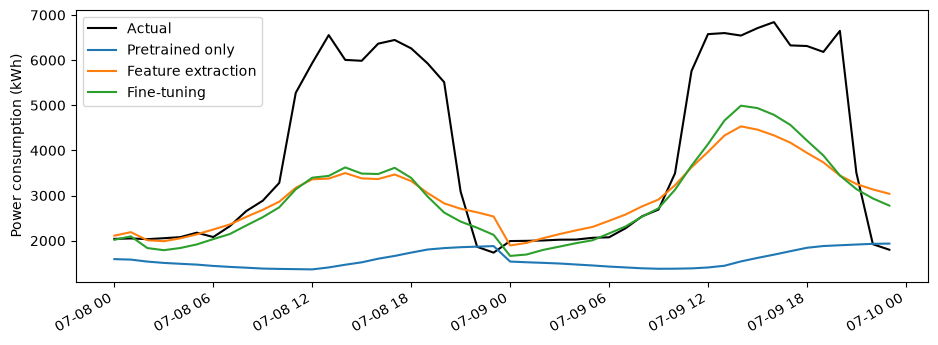

In [6]:
models = {"Pretrained only": pretrained,
          "Feature extraction": feature_model, "Fine-tuning": fine_model}
scores = target_scores(models)
print(scores)
print("검증 MSE 가장 낮은 것:", scores.loc[scores["target_valid_mse"].idxmin(), "model"])

# 각 모델의 표준화 예측값을 kWh로 되돌리세요.
pred_kwh = {}
for name, params in models.items():
    pred_kwh[name] = predict_scaled(X_valid, params).ravel() * y_std + y_mean

# 처음 5행 표와 처음 48시간 그래프를 작성하세요.
table = pd.DataFrame({"time": target_valid["time"].values,
                      "Actual": target_valid[target].values})
for name in models:
    table[name] = pred_kwh[name]
print(table.head(5))

fig, ax = plt.subplots(figsize=(11,4))
ax.plot(target_valid["time"].iloc[:48], target_valid[target].iloc[:48], label="Actual", color="black")
for name in models:
    ax.plot(target_valid["time"].iloc[:48], pred_kwh[name][:48], label=name)
ax.set_ylabel("Power consumption (kWh)")
ax.legend()
fig.autofmt_xdate()
plt.show()

#### 답안 작성 — 관찰값과 이유를 함께 쓰세요

**Q1. 세 모델의 대상 검증 MSE는 각각 얼마이며, 이번 실행에서는 어느 단계가 가장 낮나요?**

- 나의 답변: Pretrained only 7.5686, Feature extraction 2.3464, Fine-tuning 2.2395이고, 이번 실행에서는 Fine-tuning이 가장 낮았다.

- 출력값 또는 코드 근거: target_scores로 만든 scores 표의 target_valid_mse 열(검증 168행 전체, 표준화 MSE)이랑 48시간 그래프.

- 그렇게 판단한 이유: 세 모델을 같은 X_valid, y_valid로 평가했으니까 숫자를 바로 비교해도 된다. 출력층만 새로 학습해도 7.5686에서 2.3464로 크게 줄었고, 은닉층까지 조금 조정하니까 약 0.11 더 줄었다.

**Q2. Source에서 이미 학습한 모델인데도 바로 5번 건물에 적용하면 오차가 클 수 있는 이유는 무엇인가요? Fine-tuning은 언제나 더 좋은 결과를 만드나요?**

- 나의 답변: 출력층이 1번부터 4번 건물의 전력 사용 규모에 맞춰져 있어서 5번 건물 수준이랑 안 맞을 수 있다. 기간도 6월에서 7월로 바뀌어서 기온 범위가 다르다. Fine-tuning도 항상 좋아지는 건 아니고, 데이터가 적으면 과적합 때문에 비슷하거나 더 나빠질 수도 있다.

- 출력값 또는 코드 근거: 처음 5행 표를 보면 실제값은 약 2,040 kWh인데 Pretrained only 예측은 약 1,490에서 1,590 kWh로 계속 낮게 나왔다. 그래프에서도 Pretrained only 선이 실제값보다 아래에 있었다. 반대로 Fine-tuning 학습 MSE는 1.0887인데 검증 MSE는 2.2395로 차이가 있어서, 학습 데이터에만 맞춘 부분도 있는 것 같다.

- 그렇게 판단한 이유: 사전학습한 특징이 쓸모 있어도 5번 건물에 맞게 조합하는 출력층이 필요하고, 추가 조정이 도움이 되는지는 검증해봐야 알 수 있다.

**Q3. 이 표만으로 ‘사전학습을 쓰면 처음부터 학습하는 것보다 항상 좋다’고 결론 내릴 수 있나요? 최종 테스트 성능을 측정한 실험인가요?**

- 나의 답변: 그렇게 결론 내릴 수 없다. 이 표에는 처음부터 학습한 모델이 아예 없고, 건물 하나와 한 주 데이터, 한 번 실행한 결과뿐이다. 그리고 검증 데이터라서 최종 테스트 성능도 아니다.

- 출력값 또는 코드 근거: models에 Pretrained only, Feature extraction, Fine-tuning 세 개만 들어 있다. 검증 168행은 5번 건물의 7월 8일부터 14일까지다.

- 그렇게 판단한 이유: '항상'이라고 하려면 여러 건물, 기간, 초기값으로 비교해야 하고 따로 남겨둔 테스트 데이터도 있어야 한다. 처음부터 학습하는 것과의 비교는 6장 2강에서 한다.


---

## 기초 과제. 업데이트 범위만 바꾸어 확인하기


### 문제 3-1. 같은 출발점에서 동결 여부만 바꾸기

#### 문제 설명

실습의 `feature_model`을 같은 출발점으로 두고 두 가지 추가 학습을 비교합니다. 이미 계산한 Fine-tuning 결과는 재사용할 수 있습니다. 핵심은 파라미터 고정 여부와 결과를 읽는 것입니다.

| 조건 | 시작 모델 | 추가 epoch | 학습률 | train_backbone |
|---|---|---:|---:|---|
| Frozen continuation | feature_model | 100 | 0.003 | False |
| Fine-tuning | feature_model | 100 | 0.003 | True |

#### 요구사항

1. 위의 Frozen continuation 조건으로 `frozen_more, frozen_history`를 만드세요.
2. `parameter_changes(feature_model, frozen_more)`로 은닉층이 고정되었는지 확인하세요.
3. `target_scores()`로 `frozen_more`와 실습에서 계산한 `fine_model`의 대상 손실을 나란히 출력하세요.
4. 업데이트 대상 숫자 개수와 실제 검증 결과를 근거로 아래 질문에 답하세요.

#### 작성 도움말

학습 함수에 `train_backbone=False`를 전달합니다. `feature_model`을 복사해서 학습하는 함수이므로 두 비교 조건은 같은 출발점을 유지합니다. `frozen_more`에서 다시 미세조정하면 시작점이 달라지므로 이번 비교와 다릅니다.

#### 해석 질문

**Q1.** 두 조건에서 같게 유지한 것과 다르게 설정한 것은 무엇인가요? 각각 몇 개의 파라미터를 업데이트하나요?

**Q2.** Frozen continuation의 W1·b1은 바뀌었나요? 출력층의 업데이트가 있었는데도 여전히 특징 추출부가 고정된 방식인 이유는 무엇인가요?

**Q3.** 두 조건의 검증 손실 중 어느 것이 낮나요? 결과와 한계를 포함하여 2~3문장으로 설명하세요.

#### 제출 결과

고정 여부 확인 표, 두 조건의 손실 비교 표, Q1~Q3 답변.


In [7]:
frozen_more, frozen_history = train_model(feature_model, X_train, y_train,
    lr=0.003, epochs=100, train_backbone=False)
frozen_changes = parameter_changes(feature_model, frozen_more)
print(frozen_changes)
print("W1 같음:", np.array_equal(feature_model["W1"], frozen_more["W1"]))
print("b1 같음:", np.array_equal(feature_model["b1"], frozen_more["b1"]))

homework_scores = target_scores({"Frozen continuation": frozen_more, "Fine-tuning": fine_model})
homework_scores["업데이트 개수"] = [9, 65]
# 표를 출력하고 업데이트 범위와 검증 결과를 해석하세요.
print(homework_scores)

  parameter  count  max_abs_change
0        W1     48        0.000000
1        b1      8        0.000000
2        W2      8        0.037881
3        b2      1        0.003479
W1 같음: True
b1 같음: True
                 model  target_train_mse  target_valid_mse  업데이트 개수
0  Frozen continuation          1.305568          2.339512        9
1          Fine-tuning          1.088650          2.239531       65


#### 답안 작성 — 관찰값과 이유를 함께 쓰세요

**Q1. 두 조건에서 같게 유지한 것과 다르게 설정한 것은 무엇인가요? 각각 몇 개의 파라미터를 업데이트하나요?**

- 나의 답변: 시작 모델(feature_model), 학습 데이터, 학습률 0.003, epoch 100, 평가 데이터는 똑같이 두고 train_backbone만 False와 True로 다르게 했다. Frozen continuation은 9개, Fine-tuning은 65개를 업데이트한다.

- 출력값 또는 코드 근거: 두 train_model 호출 인자를 비교했고, homework_scores 표의 업데이트 개수 열이 9, 65였다.

- 그렇게 판단한 이유: 한 가지 조건만 바꿔야 결과 차이를 그 조건 때문이라고 말할 수 있다.

**Q2. Frozen continuation의 W1·b1은 바뀌었나요? 출력층의 업데이트가 있었는데도 여전히 특징 추출부가 고정된 방식인 이유는 무엇인가요?**

- 나의 답변: 안 바뀌었다. 출력층은 바뀌었지만 특징을 만드는 은닉층 W1, b1은 그대로라서 여전히 특징 추출부를 고정한 방식이다.

- 출력값 또는 코드 근거: frozen_changes에서 W1, b1 변화가 0이고 W2, b2는 0보다 컸다. W1 같음 True, b1 같음 True.

- 그렇게 판단한 이유: 동결은 모델 전체 학습을 멈추는 게 아니라 정한 부분만 안 고치는 것이기 때문이다.

**Q3. 두 조건의 검증 손실 중 어느 것이 낮나요? 결과와 한계를 포함하여 2~3문장으로 설명하세요.**

- 나의 답변: 이번 실행에서는 Fine-tuning의 검증 손실이 2.2395로 Frozen continuation 2.3395보다 0.1000 더 낮았다. Frozen continuation은 feature_model(2.3464)보다 약 0.007밖에 안 줄었는데 Fine-tuning은 약 0.107 줄어서, 같은 학습률과 횟수에서는 은닉층까지 조정한 게 도움이 된 것 같다. 하지만 한 건물, 한 주 데이터로 한 번 돌린 결과라서 학습률이나 epoch, 건물이 바뀌면 결과도 달라질 수 있다.

- 출력값 또는 코드 근거: homework_scores의 target_valid_mse: Frozen continuation 2.3395, Fine-tuning 2.2395. 학습 MSE도 1.3056 대 1.0887이었다.

- 그렇게 판단한 이유: 다른 조건을 다 같게 했으니까 차이는 은닉층을 고쳤는지 때문이라고 볼 수 있다. 그래도 차이가 0.1 정도라서 다른 데이터에서도 그렇다고 말하긴 어렵다.


---

## 실습 마무리

실습 결과를 보고 아래 여섯 질문에 자신의 말로 답하세요. 단순히 체크하는 항목이 아니라 **개념·코드·결과를 연결해 쓰는 복습 문제**입니다. 새 코드를 만들거나 심화 내용을 조사할 필요는 없습니다. 답을 먼저 작성한 뒤 정답 파일의 상세 해설과 비교하세요.

### 마무리 1. 사전학습과 전달

`initial`, `pretrained`, `feature_model`, `fine_model`의 순서를 적고 각 단계에서 사용한 데이터와 업데이트한 부분을 설명하세요. Source에서 Target으로 전달한 것은 무엇인가요?

- 나의 답변: initial(학습 안 한 무작위 값) → pretrained(1번부터 4번 건물 6월 데이터로 65개 전부 학습) → feature_model(5번 건물 대상 학습 데이터로 은닉층 고정, 새 출력층 9개만 학습) → fine_model(같은 데이터로 65개 전부 작은 학습률로 조정). Source에서 Target으로 넘긴 건 학습된 은닉층 W1, b1이다.

- 코드·수치 근거: parameter_changes(initial, pretrained)가 전부 0보다 컸고, feature_start = copy_model(pretrained)에서 W2, b2만 바꿨고, Fine-tuning은 train_model(feature_model, ..., train_backbone=True)로 했다.

- 헷갈렸던 점과 고친 설명: 처음엔 구조가 같으면 사전학습 모델인 줄 알았는데, 실제로 데이터로 학습을 끝낸 값이어야 하고 넘기는 것도 정답 데이터가 아니라 파라미터라는 걸 알게 됐다.


### 마무리 2. 특징과 파라미터

X_train의 모양이 (168,6)일 때 H와 최종 예측의 모양을 쓰세요. W1·b1·W2·b2의 숫자 개수와 전체 개수를 계산하고, H의 8개 특징이 무엇을 뜻하는지 설명하세요.

- 나의 답변: H는 (168, 8), 최종 예측은 (168, 1)이다. W1 48개, b1 8개, W2 8개, b2 1개라서 전체 65개다. H의 8개 특징은 입력 6개를 가중합하고 편향 더하고 tanh 적용해서 만든 중간 값이다.

- 코드·수치 근거: H_train.shape 출력과 parameter_changes의 count 열(48, 8, 8, 1).

- 헷갈렸던 점과 고친 설명: 168을 가중치 개수로 헷갈렸는데 168은 샘플 수고, 모든 샘플이 같은 W1, b1을 같이 쓴다.


### 마무리 3. 동결의 의미

Feature Extraction에서 W1 동일=True, b1 동일=True, H 동일=True인데도 예측값이 달라질 수 있는 이유를 설명하세요. 동결하면 은닉층을 생략한다는 설명이 맞는지도 답하세요.

- 나의 답변: 동결은 W1, b1을 안 고치는 거지 은닉층 계산을 안 하는 게 아니다. 그래서 H는 그대로인데 출력층 W2, b2가 학습돼서 예측값은 달라진다. 동결하면 은닉층을 생략한다는 설명은 틀렸다.

- 코드·수치 근거: W1 같음 True, b1 같음 True, H 같음 True인데 예측 최대 변화는 0보다 컸다.

- 헷갈렸던 점과 고친 설명: train_backbone=False의 False랑 np.array_equal 결과의 True를 헷갈렸는데, 하나는 설정이고 하나는 비교 결과라서 의미가 다르다.


### 마무리 4. 미세조정의 출발점

Fine-tuning에 feature_model을 사용하는 이유와 작은 학습률을 쓰는 이유를 설명하세요. 학습률 0.003과 train_backbone=False는 같은 의미인가요?

- 나의 답변: feature_model은 사전학습 은닉층에 5번 건물용 출력층까지 맞춰진 상태라서 거기서 시작해야 사전학습한 걸 살리면서 조금만 고칠 수 있다. 학습률을 작게 한 건 이미 좋은 값에서 너무 멀리 가거나 적은 데이터에 과적합되는 걸 막기 위해서다. 학습률 0.003과 train_backbone=False는 다르다. 앞은 얼마나 크게 바꿀지, 뒤는 은닉층을 바꿀지 말지다.

- 코드·수치 근거: Fine-tuning에서 W1 최대 변화가 0.1254로, Feature Extraction 때 W2 변화 2.0871보다 훨씬 작았다.

- 헷갈렸던 점과 고친 설명: 학습률을 낮추는 게 동결이랑 비슷한 거라고 생각했는데, 조금이라도 바뀌면 동결이 아니다.


### 마무리 5. 성능과 단위

세 단계의 대상 검증 MSE를 비교하여 이번 결과를 설명하세요. 그 MSE를 평균 kWh 오차나 모든 시간에서의 우열로 해석해도 되는지, 별도 최종 테스트 성능인지도 답하세요.

- 나의 답변: 이번 실행에서 검증 MSE는 Pretrained only 7.5686, Feature extraction 2.3464, Fine-tuning 2.2395였다. 이 MSE는 Source 평균, 표준편차로 표준화한 전력소비량으로 계산한 거라서 kWh 평균 오차가 아니고, 168행 평균이라 모든 시간에서 같은 순서라는 뜻도 아니다. 검증 데이터라서 따로 남겨둔 최종 테스트 성능도 아니다.

- 코드·수치 근거: scores 표, 처음 5행 kWh 표(실제 약 2,040 kWh, Pretrained only 약 1,500 kWh), 48시간 그래프.

- 헷갈렸던 점과 고친 설명: MSE를 그대로 kWh로 읽으면 안 되고, kWh로 보려면 예측값에 y_std를 곱하고 y_mean을 더해야 한다.


### 마무리 6. 비교 조건과 핵심 정리

과제에서 같게 유지한 조건과 바꾼 조건을 설명하고, Pretrained Model·Feature Extraction·Fine-tuning을 각각 한 문장으로 정리하세요.

- 나의 답변: 과제에서는 시작 모델, 데이터, 학습률, epoch는 같게 두고 train_backbone만 바꿨다. Pretrained Model은 관련 데이터로 이미 학습을 끝낸 모델이다. Feature Extraction은 사전학습한 은닉층을 고정해서 특징을 만들고 새 출력층만 학습하는 방식이다. Fine-tuning은 학습된 파라미터에서 시작해서 은닉층까지 대상 데이터로 조금씩 더 조정하는 방식이다.

- 코드·수치 근거: Frozen continuation 9개, Fine-tuning 65개 업데이트, 변화 표와 homework_scores.

- 헷갈렸던 점과 고친 설명: 두 방식을 따로따로 외웠는데, 결국 뭘 가져와서 뭘 고정하고 뭘 고치는지의 차이라는 걸 알게 됐다.


## 제출 전 확인

- 실습 2개와 기초 과제 1개의 출력 및 해석 질문 18개를 작성했나요?
- 실습 마무리 여섯 질문에 자신의 설명과 근거를 적었나요?
- W1·b1 고정과 H 계산을 구분하고, 56개·9개·65개를 계산할 수 있나요?
- 각 변화 표의 비교 전·후 모델을 정확히 확인했나요?
- MSE와 kWh 예측값, 전체 평균과 개별 시간 결과를 구분했나요?
- 이번 건물·기간의 결과를 모든 경우에 일반화하지 않았나요?

CSV 두 개와 노트북을 같은 폴더에 두고 처음부터 순서대로 실행합니다. 정답 파일의 저장된 출력은 제공 데이터로 실제 실행한 결과입니다. 환경에 따른 마지막 소수점 차이보다 같은 입력·비교 조건·계산 의미를 확인하세요.
